# Penutup: dari analisis menjadi dashboard interaktif

**Durasi:** sekitar 60 menit. **Hasil akhir:** dashboard ekonomi 34 provinsi
tahun 2021, berbahasa Indonesia, dengan filter, grafik, regresi, dan simulasi.

Semua langkah dijalankan dari notebook ini dengan **Shift + Enter**.
Tidak perlu membuka terminal. Streamlit menampilkan aplikasi di browser,
sedangkan notebook ini menyimpan seluruh kode aplikasinya.
Contoh tabel dan keluaran pemeriksaan dapat dibaca sebelum menjalankan ulang;
pratinjau dashboard akan aktif setelah Anda menjalankan sel server dan pratinjau.

**Di Colab:** simpan salinan notebook, lalu jalankan dari atas dengan koneksi internet.
Dashboard hanya memakai `provinsi_2021.csv`, yang dibaca langsung dari GitHub.
Di komputer sendiri, gunakan kernel yang sudah dipakai untuk materi sebelumnya.

**Posisi dalam alur workshop.** Kita menggunakan kembali membaca CSV, memilih
X/y, `LinearRegression`, dan evaluasi data uji. Tambahannya adalah tombol dan
pilihan yang memungkinkan orang lain mencoba analisis tanpa menyunting kode.



## 1. Siapkan alat dan data

Jalankan sel instalasi sekali dan tunggu sampai selesai. Versi di bawah sama
dengan lingkungan yang dipakai untuk menguji materi ini.



In [1]:
%pip install -q "streamlit==1.45.1" "plotly==5.24.1" "pandas==2.2.3" "numpy==2.1.3" "scikit-learn==1.6.1" "pyngrok==9.0.2"


Note: you may need to restart the kernel to use updated packages.


Sel berikut menetapkan alamat CSV di GitHub dan membuat folder sementara
untuk berkas aplikasi. Jalankan sel ini apa adanya. Data dibaca langsung
dari GitHub; tidak ada salinan CSV baru di folder materi.



In [2]:
import os
import tempfile
from pathlib import Path

URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

folder_dashboard = tempfile.mkdtemp(prefix="dashboard_ekonomi_")
os.chdir(folder_dashboard)
Path(".streamlit").mkdir(exist_ok=True)
Path(".streamlit/config.toml").write_text('[theme]\nprimaryColor = "#2F5D50"\n', encoding="utf-8")
print("Data dibaca langsung dari GitHub. Berkas aplikasi disimpan di folder sementara.")


Data dibaca langsung dari GitHub. Berkas aplikasi disimpan di folder sementara.


## 2. Pahami data sebelum membuat tombol

Aplikasi menggunakan empat kolom: nama provinsi, IPM, pengangguran, dan
kemiskinan. IPM adalah **poin indeks**, sedangkan pengangguran dan kemiskinan
adalah **persentase**. Satu baris mewakili satu provinsi pada **2021**.

Data mengikuti 34 provinsi pada tahun tersebut. Data ini dapat dipakai untuk
membandingkan kondisi pada 2021; tampilan dashboard tidak memperbarui angkanya
menjadi kondisi tahun berjalan.



<!-- kamus_variabel:provinsi_2021.csv -->

### Kenali data: Indikator 34 provinsi tahun 2021

**Data:** `data/provinsi_2021.csv`. **Satu baris:** satu provinsi pada tahun 2021 dalam kompilasi sumber.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Provinsi` | Nama provinsi yang diamati. | Nama wilayah | Penanda, bukan besaran ekonomi |
| `PDRB_Kapita` | Produk Domestik Regional Bruto per penduduk, ukuran output ekonomi per kapita. | Skala sumber; dipakai sebagai ribu rupiah dalam tutorial | Y atau X sesuai model |
| `IPM` | Indeks Pembangunan Manusia yang merangkum dimensi kesehatan, pendidikan, dan taraf hidup. | Poin indeks, bukan persen | Y atau X sesuai model |
| `Pengangguran` | Tingkat Pengangguran Terbuka (TPT). | Persen angkatan kerja | X: penjelas |
| `Kemiskinan` | Penduduk yang berada di bawah garis kemiskinan. | Persen penduduk | Y: target |
| `AHH_Laki` | Angka Harapan Hidup laki-laki pada kompilasi sumber. | Tahun | Indikator pendamping |
| `AHH_Perempuan` | Angka Harapan Hidup perempuan pada kompilasi sumber. | Tahun | Indikator pendamping |
| `APS_7_12` | Angka Partisipasi Sekolah penduduk umur 7 sampai 12 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `APS_13_15` | Angka Partisipasi Sekolah penduduk umur 13 sampai 15 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `APS_16_18` | Angka Partisipasi Sekolah penduduk umur 16 sampai 18 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `APS_19_23` | Angka Partisipasi Sekolah penduduk umur 19 sampai 23 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `Perokok` | Persentase perokok pada kompilasi data provinsi. | Persen; cakupan umur mengikuti sumber | Indikator pendamping |

Berkas ini adalah kompilasi indikator, bukan tabel metadata lengkap BPS. Cakupan indikator dan skala PDRB perlu diperiksa pada sumber BPS sebelum dipakai untuk riset; barisnya mengikuti 34 provinsi pada tahun 2021.

Sumber definisi: [rujukan data](https://github.com/sainsdataid/dataset/blob/main/Data%2034%20Provinsi%202021.csv).


In [3]:
import pandas as pd

data = pd.read_csv(URL_DATA + "provinsi_2021.csv")

data.head()

,Provinsi,PDRB_Kapita,IPM,Pengangguran,Kemiskinan,AHH_Laki,AHH_Perempuan,APS_7_12,APS_13_15,APS_16_18,APS_19_23,Perokok
0,Aceh,34674,72.18,6.30,15.33,70.74,74.77,99.67,98.42,83.28,34.95,28.30
1,Sumatera Utara,57442,72.00,6.33,9.01,71.07,75.23,99.32,96.99,78.66,29.34,27.24
2,Sumatera Barat,45218,72.65,6.52,6.63,71.40,75.91,99.61,96.63,84.07,39.40,30.50
3,Riau,129741,72.94,4.42,7.12,71.47,76.08,99.65,95.66,77.81,30.38,28.34
4,Jambi,64771,71.63,5.09,8.09,71.25,75.61,99.66,96.39,72.50,25.63,27.47


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
kolom_dashboard = ["Provinsi", "IPM", "Pengangguran", "Kemiskinan"]
data[kolom_dashboard].head()



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

### Lihat hasil yang akan dibawa ke dashboard

Sebelum menulis tombol, kita periksa dua tampilan: perbandingan provinsi dan hubungan IPM dengan kemiskinan.

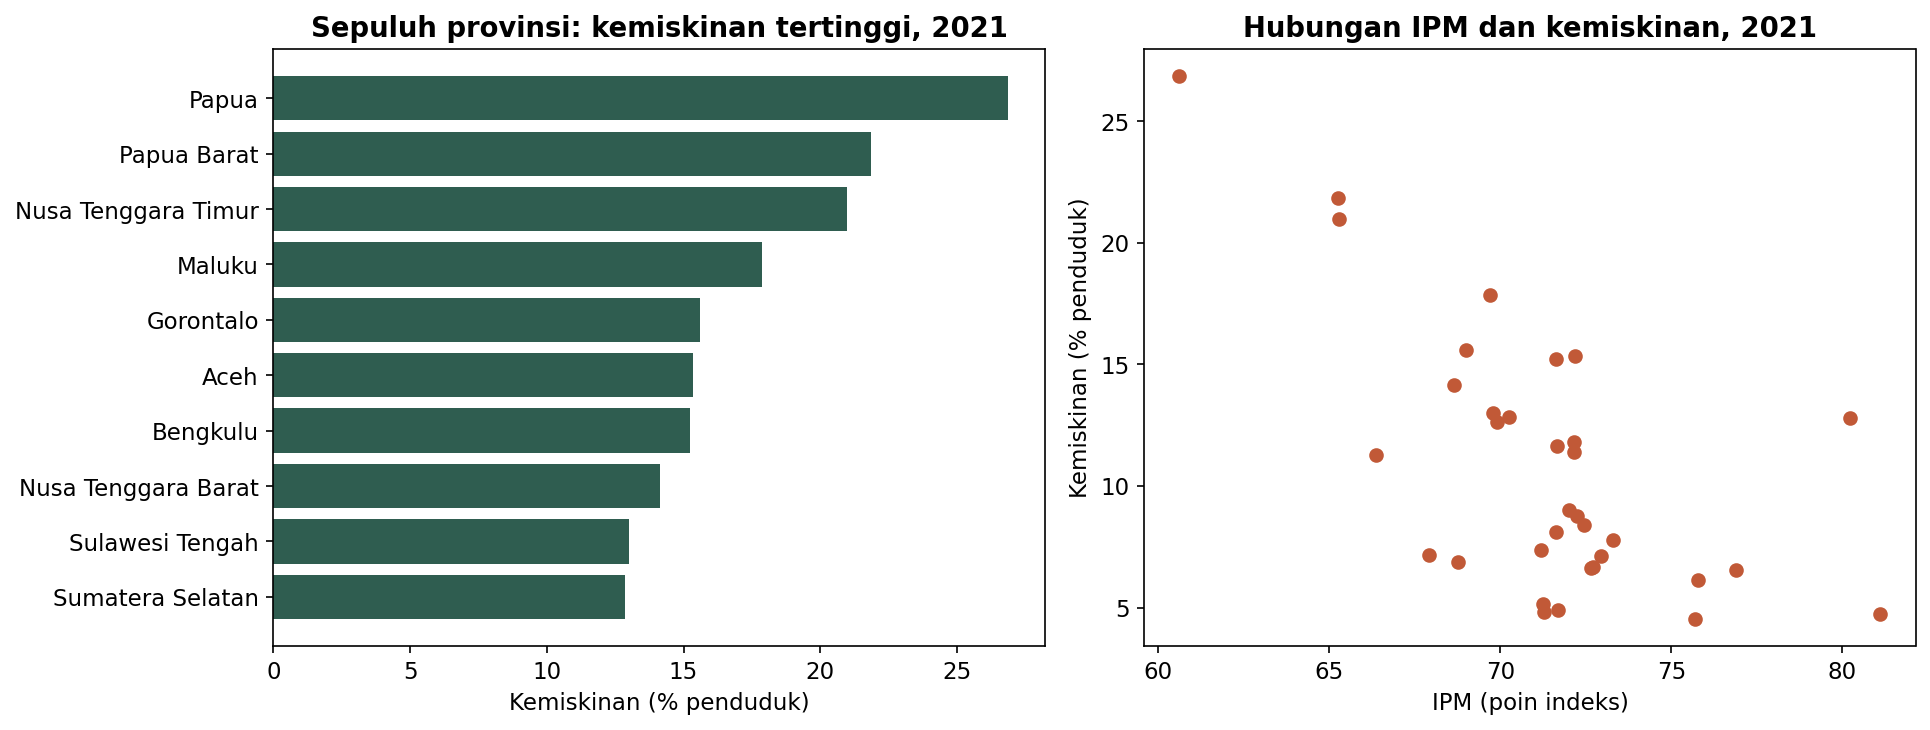

In [5]:
import matplotlib.pyplot as plt
sepuluh_provinsi = data.nlargest(10, "Kemiskinan").sort_values("Kemiskinan")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(sepuluh_provinsi["Provinsi"], sepuluh_provinsi["Kemiskinan"], color="#2F5D50")
axes[0].set(xlabel="Kemiskinan (% penduduk)", title="Sepuluh provinsi: kemiskinan tertinggi, 2021")
axes[1].scatter(data["IPM"], data["Kemiskinan"], color="#C15937")
axes[1].set(xlabel="IPM (poin indeks)", ylabel="Kemiskinan (% penduduk)", title="Hubungan IPM dan kemiskinan, 2021")
plt.tight_layout()
plt.show()

**Cara membaca:** Panel kiri hanya menampilkan sepuluh provinsi, sedangkan panel kanan memakai seluruh 34 provinsi. Persentase kemiskinan bukan jumlah orang miskin. Hubungan pada panel kanan masih deskriptif; aplikasi berikut menambahkan filter dan pemodelan.

## 3. Menulis halaman utama dan filter

`%%writefile bagian_01.py` menyimpan isi sel sebagai bagian pertama aplikasi.
Baris ini harus tetap berada di **baris pertama sel**. Semua baris sesudahnya
adalah kode Python aplikasi, bukan perintah yang diketik di terminal.

| Perintah Streamlit | Yang terlihat oleh pengguna |
|---|---|
| `st.title(...)` | Judul halaman. |
| `st.sidebar.multiselect(...)` | Daftar provinsi yang dapat dipilih. |
| `st.metric(...)` | Angka ringkasan. |
| `st.tabs(...)` | Tab untuk berpindah bagian. |

Baca alurnya: muat CSV, pilih provinsi, hitung rata-rata, lalu siapkan tiga tab.
`st.stop()` menghentikan bagian selanjutnya jika pengguna belum memilih provinsi.



In [6]:
%%writefile bagian_01.py
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

st.set_page_config(page_title="Ekonomi Provinsi Indonesia", layout="wide")
st.title("Ekonomi Provinsi Indonesia")
st.caption("34 provinsi · Data tahun 2021 · Praktik ekonometrika dengan Python")

data = pd.read_csv(URL_DATA + "provinsi_2021.csv")
data = data[["Provinsi", "IPM", "Pengangguran", "Kemiskinan"]].dropna()

st.sidebar.header("Pilih data")
semua_provinsi = st.sidebar.checkbox("Tampilkan semua provinsi", value=True, key="semua_provinsi")
if semua_provinsi:
    provinsi = data["Provinsi"].tolist()
else:
    provinsi = st.sidebar.multiselect(
        "Provinsi yang ditampilkan", data["Provinsi"].tolist(),
        default=["Jambi"], key="provinsi",
    )
indikator = st.sidebar.selectbox(
    "Indikator untuk peringkat", ["Kemiskinan", "IPM", "Pengangguran"], key="indikator",
)
data_pilihan = data[data["Provinsi"].isin(provinsi)].copy()

if data_pilihan.empty:
    st.info("Pilih sedikitnya satu provinsi melalui panel di sebelah kiri.")
    st.stop()

st.write(f"Menampilkan **{len(data_pilihan)} provinsi** sesuai pilihan Anda.")
kolom1, kolom2, kolom3 = st.columns(3)
kolom1.metric("IPM (poin)", f"{data_pilihan['IPM'].mean():.2f}")
kolom2.metric("Pengangguran (%)", f"{data_pilihan['Pengangguran'].mean():.2f}%")
kolom3.metric("Kemiskinan (%)", f"{data_pilihan['Kemiskinan'].mean():.2f}%")
st.caption("Ringkasan adalah rata-rata sederhana antarprovinsi terpilih; pembobotan penduduk tidak digunakan.")

tab_grafik, tab_model, tab_data = st.tabs(["Jelajah provinsi", "Regresi dan simulasi", "Data dan arti variabel"])


Writing bagian_01.py


## 4. Menambahkan grafik interaktif

Setiap sel `%%writefile` menyimpan satu bagian aplikasi. Sel dapat dijalankan
ulang karena isinya mengganti bagian sebelumnya. Sel server pada langkah 7
akan menyatukan semua bagian menjadi aplikasi lengkap secara otomatis.

Grafik batang memperlihatkan paling banyak 10 provinsi dengan nilai tertinggi
pada indikator yang dipilih. Nilai tinggi IPM dan nilai tinggi kemiskinan
mempunyai arti berbeda; jelaskan indikatornya sebelum menyebut kondisi baik/buruk.
Arahkan kursor ke titik scatter untuk melihat nama provinsinya.



In [7]:
%%writefile bagian_02.py

with tab_grafik:
    st.subheader("Peringkat indikator")
    satuan = "persen"
    if indikator == "IPM":
        satuan = "poin indeks"
    peringkat = data_pilihan.nlargest(10, indikator).sort_values(indikator)
    grafik_peringkat = px.bar(
        peringkat, x=indikator, y="Provinsi", orientation="h",
        color_discrete_sequence=["#2F5D50"],
        labels={indikator: indikator + " (" + satuan + ")"},
    )
    st.plotly_chart(grafik_peringkat, use_container_width=True)

    st.subheader("Hubungan dua indikator")
    sumbu_x = st.selectbox("Sumbu X", ["IPM", "Pengangguran"], key="sumbu_x")
    grafik_hubungan = px.scatter(
        data_pilihan, x=sumbu_x, y="Kemiskinan", hover_name="Provinsi",
        color_discrete_sequence=["#C15937"],
        labels={"IPM": "IPM (poin)", "Pengangguran": "Pengangguran (%)", "Kemiskinan": "Kemiskinan (%)"},
    )
    st.plotly_chart(grafik_hubungan, use_container_width=True)
    st.caption("Setiap titik adalah satu provinsi pada 2021. Pola hubungan statistik belum menunjukkan sebab akibat.")


Writing bagian_02.py


## 5. Menambahkan regresi dan simulasi

Pola modelnya sama dengan materi sebelumnya: pilih X/y, bagi data, buat
`LinearRegression`, jalankan `fit`, lalu `predict`. Target y adalah kemiskinan.
Pengguna dapat memilih IPM, pengangguran, atau keduanya sebagai X.

Model menggunakan provinsi yang dipilih pada panel kiri. **75%** menjadi data
latih dan **25%** menjadi data uji. Koefisien dan simulasi berasal dari model
yang dilatih pada data latih tersebut. Baris simulasi memakai urutan fitur yang sama.

**RMSE** dibaca dalam poin persentase kemiskinan. **R² data uji** dapat negatif.
RMSE pembanding memakai rata-rata kemiskinan data latih untuk semua provinsi uji.
Jumlah provinsi sedikit, sehingga nilai evaluasi dapat berubah cukup besar saat
pilihan provinsi berubah. Model ini adalah contoh pembelajaran.



In [8]:
%%writefile bagian_03.py

with tab_model:
    st.subheader("Model kemiskinan")
    fitur = st.multiselect(
        "Variabel penjelas (X)", ["IPM", "Pengangguran"],
        default=["IPM", "Pengangguran"], key="fitur",
    )

    if not fitur:
        st.info("Pilih sedikitnya satu variabel penjelas.")
    elif len(data_pilihan) < 10:
        st.info("Pilih sedikitnya 10 provinsi untuk latihan regresi dan evaluasi.")
    elif (data_pilihan[fitur].nunique() < 2).any():
        st.info("Variabel X harus mempunyai lebih dari satu nilai pada data terpilih.")
    else:
        X = data_pilihan[fitur]
        y = data_pilihan["Kemiskinan"]
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=42,
        )
        model = LinearRegression()
        model.fit(X_train, y_train)
        prediksi_uji = model.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, prediksi_uji))
        r2 = r2_score(y_test, prediksi_uji)
        pembanding = np.repeat(y_train.mean(), len(y_test))
        rmse_pembanding = np.sqrt(mean_squared_error(y_test, pembanding))

        hasil1, hasil2 = st.columns(2)
        hasil1.metric("RMSE uji (poin persen)", f"{rmse:.2f}")
        hasil2.metric("R² data uji", f"{r2:.3f}")
        st.write(f"RMSE pembanding rata-rata: **{rmse_pembanding:.2f} poin persen**.")
        st.caption(f"Data latih: {len(X_train)} provinsi. Data uji: {len(X_test)} provinsi. RMSE lebih kecil menunjukkan error yang lebih kecil.")

        with st.expander("Lihat koefisien dan hasil data uji"):
            koefisien = pd.Series(model.coef_, index=fitur, name="Koefisien")
            koefisien.loc["Intersep"] = model.intercept_
            st.dataframe(koefisien.to_frame(), use_container_width=True)
            st.caption("Koefisien menunjukkan perubahan prediksi kemiskinan dalam poin persen untuk tambahan 1 poin IPM atau 1 poin persen pengangguran, dengan X lain tetap.")
            hasil_uji = data_pilihan.loc[X_test.index, ["Provinsi", "Kemiskinan"]].copy()
            hasil_uji["Prediksi_Kemiskinan"] = prediksi_uji
            st.dataframe(hasil_uji, hide_index=True, use_container_width=True)

        st.subheader("Coba skenario Anda")
        profil = pd.DataFrame({
            "IPM": [data_pilihan["IPM"].mean()],
            "Pengangguran": [data_pilihan["Pengangguran"].mean()],
        })
        if "IPM" in fitur:
            profil.loc[0, "IPM"] = st.slider(
                "IPM skenario (poin)", float(X_train["IPM"].min()), float(X_train["IPM"].max()),
                float(X_train["IPM"].mean()), key="ipm_skenario",
            )
        if "Pengangguran" in fitur:
            profil.loc[0, "Pengangguran"] = st.slider(
                "Pengangguran skenario (%)", float(X_train["Pengangguran"].min()), float(X_train["Pengangguran"].max()),
                float(X_train["Pengangguran"].mean()), key="pengangguran_skenario",
            )
        prediksi_baru = float(model.predict(profil[fitur])[0])
        st.metric("Prediksi kemiskinan skenario", f"{prediksi_baru:.2f}%")
        st.caption("Simulasi mengikuti pola antarprovinsi pada 2021. Hasilnya bersifat deskriptif dan memiliki ketidakpastian.")
        if prediksi_baru < 0 or prediksi_baru > 100:
            st.warning("Prediksi di luar 0–100%. Model linear tidak membatasi hasil pada rentang persentase.")


Writing bagian_03.py


## 6. Menambahkan tabel, definisi, dan unduhan

Tombol unduhan menyimpan data **sesuai filter provinsi**. `index=False`
mencegah nomor baris ikut menjadi kolom baru di CSV.



In [9]:
%%writefile bagian_04.py

with tab_data:
    st.subheader("Arti variabel yang digunakan")
    st.markdown("""
| Variabel | Pengertian | Satuan atau peran |
|---|---|---|
| Provinsi | Nama wilayah pada data 2021. | Penanda pengamatan. |
| IPM | Indeks Pembangunan Manusia: kesehatan, pendidikan, dan taraf hidup. | Poin indeks; calon X. |
| Pengangguran | Tingkat Pengangguran Terbuka. | Persen angkatan kerja; calon X. |
| Kemiskinan | Persentase penduduk di bawah garis kemiskinan. | Persen penduduk; target y. |
""")
    st.subheader("Data sesuai pilihan")
    st.dataframe(data_pilihan, hide_index=True, use_container_width=True)
    st.download_button(
        "Unduh data pilihan (CSV)", data_pilihan.to_csv(index=False).encode("utf-8-sig"),
        file_name="data_provinsi_pilihan.csv", mime="text/csv",
    )
    st.caption("Sumber: kompilasi indikator provinsi 2021 yang sudah disertakan dalam paket tutorial. Data pada dashboard memakai rata-rata dan perbandingan antarprovinsi.")
    st.link_button("Buka sumber kompilasi data", "https://github.com/sainsdataid/dataset/blob/main/Data%2034%20Provinsi%202021.csv")


Writing bagian_04.py


## 7. Jalankan dashboard dari notebook

Jalankan sel berikut apa adanya. Python menyalakan Streamlit di latar belakang
dan memeriksa apakah aplikasinya sudah siap. `proses_dashboard` menyimpan proses
yang dijalankan notebook ini; menjalankan ulang sel akan mengganti proses miliknya.
Tidak perlu menyalin perintah apa pun ke terminal.



In [10]:
import socket
import subprocess
import sys

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

kode_aplikasi = (
    Path("bagian_01.py").read_text(encoding="utf-8") + "\n"
    + Path("bagian_02.py").read_text(encoding="utf-8") + "\n"
    + Path("bagian_03.py").read_text(encoding="utf-8") + "\n"
    + Path("bagian_04.py").read_text(encoding="utf-8")
)
Path("dashboard_ekonomi.py").write_text(kode_aplikasi, encoding="utf-8")

if "proses_dashboard" in globals() and proses_dashboard.poll() is None:
    proses_dashboard.terminate()
    proses_dashboard.wait(timeout=10)
if "log_dashboard" in globals():
    log_dashboard.close()

soket = socket.socket()
soket.bind(("127.0.0.1", 0))
port_dashboard = soket.getsockname()[1]
soket.close()

opsi_jendela = 0
if os.name == "nt":
    opsi_jendela = subprocess.CREATE_NO_WINDOW

log_dashboard = Path("dashboard.log").open("w", encoding="utf-8")
proses_dashboard = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "dashboard_ekonomi.py",
     "--server.port", str(port_dashboard), "--server.address", "127.0.0.1",
     "--server.headless", "true", "--browser.gatherUsageStats", "false"],
    stdout=log_dashboard, stderr=subprocess.STDOUT, creationflags=opsi_jendela,
)
alamat_dashboard = f"http://127.0.0.1:{port_dashboard}"
sesi = requests.Session()
sesi.mount("http://", HTTPAdapter(max_retries=Retry(total=8, backoff_factor=0.1)))
status = sesi.get(alamat_dashboard + "/_stcore/health", timeout=3)
status.raise_for_status()
print("Dashboard siap. Jalankan sel pratinjau berikutnya.")


Dashboard siap. Jalankan sel pratinjau berikutnya.


## 8. Buka dan coba hasilnya

Di Colab, dashboard muncul **di dalam keluaran notebook**. Jika diminta izin
mengakses server runtime, izinkan akses untuk notebook ini. Di Jupyter/VS Code,
gunakan pratinjau atau tautan lokal yang ditampilkan. Runtime harus tetap aktif.



In [11]:
from IPython.display import IFrame, display

try:
    from google.colab import output
except ImportError:
    print("Buka dashboard:", alamat_dashboard)
    display(IFrame(alamat_dashboard, width="100%", height=950))
else:
    output.serve_kernel_port_as_iframe(port_dashboard, height=950)


Buka dashboard: http://127.0.0.1:50782


## 9. Pilihan tambahan: buka dashboard melalui ngrok

Ngrok membuat tautan HTTPS agar dashboard dapat dibuka dari browser atau perangkat lain.
Jalankan langkah 7 terlebih dahulu. Untuk menggunakan tautan ini, ubah
`gunakan_ngrok = False` menjadi `True`, lalu jalankan sel berikut.
Authtoken pengajar sudah diisi langsung pada `token_ngrok` di sel berikut.
Sel tidak meminta input token atau membaca pengaturan lingkungan.

Pratinjau dan ngrok berada dalam notebook yang sama: `01_dashboard_ekonomi.ipynb`.
Cukup aktifkan `gunakan_ngrok`, lalu jalankan sel; token tidak perlu diketik ulang.

Setelah tautan muncul, klik **Buka dashboard melalui ngrok**. Jika muncul halaman
pemberitahuan ngrok, klik **Visit Site**. Biarkan runtime/notebook tetap aktif
selama tautan digunakan. Untuk memperbarui dashboard, jalankan lagi langkah 7 dan 9.

Rujukan: [panduan ngrok untuk Colab](https://ngrok.com/docs/using-ngrok-with/googleColab)
dan [API pyngrok](https://pyngrok.readthedocs.io/en/latest/api.html).



In [12]:
from IPython.display import Markdown
from pyngrok import conf, ngrok

gunakan_ngrok = False
token_ngrok = "1hk7E7tEROd5r6CDz1SN2jLSjSX_u3Xo1UALKTeCUeitEAqy"

if gunakan_ngrok:
    # Folder sementara memisahkan koneksi notebook ini dari aplikasi lain.
    konfigurasi_ngrok = conf.PyngrokConfig(
        ngrok_path=folder_dashboard + "/" + os.path.basename(conf.get_default().ngrok_path),
        config_path=folder_dashboard + "/ngrok.yml",
    )
    ngrok.kill(pyngrok_config=konfigurasi_ngrok)
    ngrok.set_auth_token(token_ngrok, pyngrok_config=konfigurasi_ngrok)
    tunnel_ngrok = ngrok.connect(alamat_dashboard, "http", pyngrok_config=konfigurasi_ngrok)
    alamat_ngrok = tunnel_ngrok.public_url
    display(Markdown(f"[Buka dashboard melalui ngrok]({alamat_ngrok})"))
    print("Tautan ngrok aktif selama runtime dan server dashboard berjalan.")
else:
    print("Pratinjau notebook tetap tersedia. Ubah gunakan_ngrok menjadi True untuk membuka tautan ngrok.")


Pratinjau notebook tetap tersedia. Ubah gunakan_ngrok menjadi True untuk membuka tautan ngrok.


### Tantangan penutup: presentasi hasil dalam dua menit

1. Pada tab **Jelajah provinsi**, pilih IPM, lalu jelaskan satu pola yang terlihat.
2. Gunakan semua provinsi, lalu bandingkan model **IPM saja** dengan model
   **IPM dan pengangguran**. Apakah RMSE uji lebih kecil daripada pembanding?
3. Ubah slider IPM. Jelaskan perubahan prediksi dalam **poin persentase** dan
   sebutkan mengapa hasil ini belum dapat disebut dampak kausal kebijakan.
4. Unduh tabel hasil filter dan tunjukkan bahwa isinya sesuai provinsi pilihan.

**Coba sendiri:** ubah judul halaman pada langkah 3. Jalankan kembali semua
sel pembuatan aplikasi (langkah 3 sampai 6), lalu jalankan ulang langkah 7 dan 8.

| Jika terjadi kendala | Langkah yang dilakukan |
|---|---|
| CSV belum terbaca | Periksa koneksi internet, lalu ulangi sel alamat data dan pembacaan CSV. |
| Perubahan judul belum terlihat | Ulangi sel bagian yang disunting, lalu sel server dan pratinjau. |
| Pratinjau kosong | Pastikan sel server selesai, izinkan akses runtime, lalu ulangi sel pratinjau. |
| Runtime dimulai ulang | Jalankan kembali notebook dari sel pertama. |
| Tautan ngrok belum muncul | Ubah gunakan_ngrok menjadi True, lalu jalankan langkah 9 setelah server siap. |
| Autentikasi ngrok ditolak | Periksa authtoken akun ngrok; gunakan token yang masih aktif. |
| Tautan ngrok berhenti | Pastikan runtime aktif, lalu ulangi langkah 7 dan 9. |
| Pilihan provinsi kosong | Pilih kembali provinsi atau centang Tampilkan semua provinsi. |
| Model belum muncul | Pilih minimal 10 provinsi dan sedikitnya satu X. |

Rujukan: [Streamlit](https://docs.streamlit.io/),
[pratinjau port Colab](https://github.com/googlecolab/colabtools/blob/main/google/colab/output/_util.py),
dan [data provinsi](https://github.com/sainsdataid/dataset/blob/main/Data%2034%20Provinsi%202021.csv).



## 10. Hentikan setelah selesai mengajar

Nilai awal `False` membuat dashboard tetap hidup ketika **Run all** dipakai.
Setelah selesai mencoba, ubah menjadi `True` dan jalankan hanya sel ini.



In [13]:
hentikan_dashboard = False

if hentikan_dashboard:
    if "konfigurasi_ngrok" in globals():
        ngrok.kill(pyngrok_config=konfigurasi_ngrok)
    if "proses_dashboard" in globals() and proses_dashboard.poll() is None:
        proses_dashboard.terminate()
        proses_dashboard.wait(timeout=10)
    if "log_dashboard" in globals():
        log_dashboard.close()
    print("Dashboard dan koneksi ngrok sudah dihentikan.")
else:
    print("Dashboard tetap aktif. Setelah selesai, ubah hentikan_dashboard menjadi True.")


Dashboard tetap aktif. Setelah selesai, ubah hentikan_dashboard menjadi True.
